<a href="https://colab.research.google.com/github/Blackk-dotcom/Data-Science-project/blob/main/A1_Student_Performance_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

np.random.seed(42)

# Correct file path for Google Colab
file_path = "/content/DSA1101_Practical_Assignments_Datasets.xlsx"

# Check whether the file exists
print("File exists:", os.path.exists(file_path))

# Load the worksheet
df = pd.read_excel(
    file_path,
    sheet_name="A1_Student_Performance"
)

print("Dataset shape:", df.shape)
display(df.head(10))


File exists: True
Dataset shape: (182, 10)


,Student_ID,Programme,Gender,Study_Hours_Per_Week,Attendance_Percent,Assignment_Average,Exam_Score,Sleep_Hours_Per_Night,Device_Access,Internet_Access
0,STU001,Computer Science,Male,8.6,84.7,77.3,67.6,6.4,Laptop,Reliable
1,STU002,IT,Female,4.4,87.1,53.9,51.7,4.7,Phone only,Reliable
2,STU003,Computer Science,Male,5.0,71.3,52.9,47.0,7.9,Laptop,Intermittent
3,STU004,IT,Male,NaN,67.1,72.7,39.7,7.4,Laptop,Reliable
4,STU005,IT,Female,12.7,78.6,68.0,81.9,7.2,Laptop,Reliable
5,STU006,Statistics,Male,35.0,79.7,63.6,72.4,6.7,Laptop,Reliable
6,STU007,IT,Male,5.3,91.8,66.7,30.2,7.2,Laptop,Intermittent
7,STU008,Statistics,Male,4.9,94.8,48.0,39.5,7.8,Laptop,Reliable
8,STU009,Statistics,Female,8.6,100.0,72.9,57.2,7.5,Laptop,Intermittent
9,STU010,Statistics,Male,8.1,91.7,57.5,46.4,7.9,Laptop,Intermittent


In [5]:

# Part A: Environment setup

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent random seed
np.random.seed(42)

# Set visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Environment ready.")


Libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.1.3
Environment ready.


In [6]:

from google.colab import files
import os

# Upload the Excel workbook if it is not already available
file_path = "/content/DSA1101_Practical_Assignments_Datasets.xlsx"

if not os.path.exists(file_path):
    uploaded = files.upload()
    file_path = next(iter(uploaded.keys()))

# Read the required worksheet
df = pd.read_excel(
    file_path,
    sheet_name="A1_Student_Performance",
    engine="openpyxl"
)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)



Dataset loaded successfully!
Number of rows and columns: (182, 10)


### Dataset Description and Provenance

The A1_Student_Performance dataset is synthetic teaching data supplied in the DSA 1101 practical assignment workbook. It represents student learning patterns, including study habits, access to learning resources, attendance, and academic performance. It is not a real institutional student record.

Primary data are collected directly by a researcher for a particular study, for example through questionnaires administered to students. Secondary data are obtained from information that has already been collected or compiled, such as existing reports, databases, or research repositories.

The supplied dataset is used for educational analysis. Its results should not be interpreted as evidence about actual students or a real university population.

In [7]:

# Create a preliminary data dictionary
data_dictionary = pd.DataFrame({
    "Variable": df.columns,
    "Data Type": [str(df[col].dtype) for col in df.columns],
    "Example Value": [
        df[col].dropna().iloc[0]
        if not df[col].dropna().empty
        else "No available value"
        for col in df.columns
    ]
})

display(data_dictionary)


,Variable,Data Type,Example Value
0,Student_ID,object,STU001
1,Programme,object,Computer Science
2,Gender,object,Male
3,Study_Hours_Per_Week,float64,8.6
4,Attendance_Percent,float64,84.7
5,Assignment_Average,float64,77.3
6,Exam_Score,float64,67.6
7,Sleep_Hours_Per_Night,float64,6.4
8,Device_Access,object,Laptop
9,Internet_Access,object,Reliable


In [8]:

# Keep an unchanged copy of the original dataset
df_raw = df.copy(deep=True)

# Create a separate dataframe for cleaning later
df_clean = df_raw.copy(deep=True)

print("Original rows:", len(df_raw))
print("Working copy rows:", len(df_clean))
print("Original dataset preserved:", df_raw.equals(df))



Original rows: 182
Working copy rows: 182
Original dataset preserved: True


In [9]:

# Count missing values and calculate their percentages
missing_summary = pd.DataFrame({
    "Missing_Count": df_raw.isna().sum(),
    "Missing_Percent": (df_raw.isna().mean() * 100).round(2)
})

display(missing_summary)



,Missing_Count,Missing_Percent
Student_ID,0,0.00
Programme,0,0.00
Gender,0,0.00
Study_Hours_Per_Week,6,3.30
Attendance_Percent,4,2.20
Assignment_Average,5,2.75
Exam_Score,0,0.00
Sleep_Hours_Per_Night,0,0.00
Device_Access,0,0.00
Internet_Access,4,2.20


In [10]:

# Exact duplicate rows
exact_duplicates = df_raw.duplicated().sum()

# Repeated Student_ID values, including every occurrence
repeated_id_rows = df_raw[
    df_raw["Student_ID"].duplicated(keep=False)
].sort_values("Student_ID")

print("Exact duplicate rows:", exact_duplicates)
print("Rows with repeated Student_ID:", len(repeated_id_rows))
print("Number of distinct repeated IDs:",
      repeated_id_rows["Student_ID"].nunique())

display(repeated_id_rows)



Exact duplicate rows: 2
Rows with repeated Student_ID: 4
Number of distinct repeated IDs: 2


,Student_ID,Programme,Gender,Study_Hours_Per_Week,Attendance_Percent,Assignment_Average,Exam_Score,Sleep_Hours_Per_Night,Device_Access,Internet_Access
12,STU013,Computer Science,Male,5.8,100.0,71.2,49.4,5.7,Laptop,Reliable
180,STU013,Computer Science,Male,5.8,100.0,71.2,49.4,5.7,Laptop,Reliable
44,STU045,Statistics,Male,5.9,96.7,85.7,69.7,7.5,Shared computer,Reliable
181,STU045,Statistics,Male,5.9,96.7,85.7,69.7,7.5,Shared computer,Reliable


In [11]:

# Define validity checks
invalid_checks = {
    "Study_Hours_Per_Week":
        (df_raw["Study_Hours_Per_Week"] < 0) |
        (df_raw["Study_Hours_Per_Week"] > 168),

    "Attendance_Percent":
        (df_raw["Attendance_Percent"] < 0) |
        (df_raw["Attendance_Percent"] > 100),

    "Assignment_Average":
        (df_raw["Assignment_Average"] < 0) |
        (df_raw["Assignment_Average"] > 100),

    "Exam_Score":
        (df_raw["Exam_Score"] < 0) |
        (df_raw["Exam_Score"] > 100)
}

for column, mask in invalid_checks.items():
    print(f"\n{column}: {mask.sum()} invalid records")
    display(df_raw.loc[mask, ["Student_ID", column]])




Study_Hours_Per_Week: 0 invalid records


,Student_ID,Study_Hours_Per_Week



Attendance_Percent: 1 invalid records


,Student_ID,Attendance_Percent
27,STU028,130.0



Assignment_Average: 0 invalid records


,Student_ID,Assignment_Average



Exam_Score: 0 invalid records


,Student_ID,Exam_Score


In [12]:

quality_audit = pd.DataFrame([
    {
        "Issue": "Missing values",
        "Affected Columns": ", ".join(
            df_raw.columns[df_raw.isna().any()].tolist()
        ),
        "Potential Consequence": "Reduced usable data or biased summaries",
        "Proposed Action": "Assess missingness and compare justified treatments"
    },
    {
        "Issue": "Exact duplicate rows",
        "Affected Columns": "All columns",
        "Potential Consequence": "Repeated records may distort analysis",
        "Proposed Action": "Remove exact duplicates after verification"
    },
    {
        "Issue": "Repeated Student_ID",
        "Affected Columns": "Student_ID",
        "Potential Consequence": "May create ambiguity when identifying students",
        "Proposed Action": "Inspect repeated records before deciding how to handle them"
    },
    {
        "Issue": "Out-of-range numerical values",
        "Affected Columns": "Study hours, attendance, assignment and exam scores",
        "Potential Consequence": "Invalid values can distort statistics and plots",
        "Proposed Action": "Flag, investigate, and document any correction or exclusion"
    }
])

display(quality_audit)



,Issue,Affected Columns,Potential Consequence,Proposed Action
0,Missing values,"Study_Hours_Per_Week, Attendance_Percent, Assi...",Reduced usable data or biased summaries,Assess missingness and compare justified treat...
1,Exact duplicate rows,All columns,Repeated records may distort analysis,Remove exact duplicates after verification
2,Repeated Student_ID,Student_ID,May create ambiguity when identifying students,Inspect repeated records before deciding how t...
3,Out-of-range numerical values,"Study hours, attendance, assignment and exam s...",Invalid values can distort statistics and plots,"Flag, investigate, and document any correction..."


In [14]:

# Start with a fresh copy of the raw data
df_clean = df_raw.copy(deep=True)

rows_before = len(df_clean)

# 1. Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# 2. Mark impossible numerical values as missing
# Keep the raw values unchanged in df_raw.
range_limits = {
    "Study_Hours_Per_Week": (0, 168),
    "Attendance_Percent": (0, 100),
    "Assignment_Average": (0, 100),
    "Exam_Score": (0, 100)
}

for column, (lower, upper) in range_limits.items():
    invalid = (
        (df_clean[column] < lower) |
        (df_clean[column] > upper)
    )
    df_clean.loc[invalid, column] = np.nan

# 3. Represent missing categorical access information explicitly
categorical_columns = ["Programme", "Gender",
                       "Device_Access", "Internet_Access"]

for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna("Unknown")

print("Rows before cleaning:", rows_before)
print("Rows after removing exact duplicates:", len(df_clean))
print("Rows removed:", rows_before - len(df_clean))

print("\nRemaining missing values:")
display(df_clean.isna().sum().to_frame("Missing_Count"))

print("\nRepeated IDs still requiring investigation:")
display(
    df_clean[df_clean["Student_ID"].duplicated(keep=False)]
    .sort_values("Student_ID")
)



Rows before cleaning: 182
Rows after removing exact duplicates: 180
Rows removed: 2

Remaining missing values:


,Missing_Count
Student_ID,0
Programme,0
Gender,0
Study_Hours_Per_Week,6
Attendance_Percent,5
Assignment_Average,5
Exam_Score,0
Sleep_Hours_Per_Night,0
Device_Access,0
Internet_Access,0



Repeated IDs still requiring investigation:


,Student_ID,Programme,Gender,Study_Hours_Per_Week,Attendance_Percent,Assignment_Average,Exam_Score,Sleep_Hours_Per_Night,Device_Access,Internet_Access


In [15]:

# Choose numerical variables for the comparison
numeric_columns = [
    "Study_Hours_Per_Week",
    "Attendance_Percent",
    "Assignment_Average",
    "Exam_Score",
    "Sleep_Hours_Per_Night"
]

# Option A: Median imputation
df_median = df_clean.copy()

for column in numeric_columns:
    df_median[column] = df_median[column].fillna(
        df_median[column].median()
    )

# Option B: Exclude rows missing any selected numerical variable
df_excluded = df_clean.dropna(
    subset=numeric_columns
).copy()

comparison = pd.DataFrame({
    "Method": ["Cleaned data before imputation",
               "Median imputation",
               "Complete-case row exclusion"],
    "Rows": [
        len(df_clean),
        len(df_median),
        len(df_excluded)
    ],
    "Exam Score Mean": [
        df_clean["Exam_Score"].mean(),
        df_median["Exam_Score"].mean(),
        df_excluded["Exam_Score"].mean()
    ]
})

display(comparison.round(2))


,Method,Rows,Exam Score Mean
0,Cleaned data before imputation,180,59.39
1,Median imputation,180,59.39
2,Complete-case row exclusion,165,59.57


In [16]:

# Summarize the cleaning results
before_after = pd.DataFrame({
    "Measure": [
        "Number of rows",
        "Exact duplicate rows",
        "Missing cells",
        "Invalid attendance values",
        "Invalid assignment scores",
        "Invalid exam scores"
    ],
    "Before": [
        len(df_raw),
        df_raw.duplicated().sum(),
        df_raw.isna().sum().sum(),
        ((df_raw["Attendance_Percent"] < 0) |
         (df_raw["Attendance_Percent"] > 100)).sum(),
        ((df_raw["Assignment_Average"] < 0) |
         (df_raw["Assignment_Average"] > 100)).sum(),
        ((df_raw["Exam_Score"] < 0) |
         (df_raw["Exam_Score"] > 100)).sum()
    ],
    "After": [
        len(df_clean),
        df_clean.duplicated().sum(),
        df_clean.isna().sum().sum(),
        ((df_clean["Attendance_Percent"] < 0) |
         (df_clean["Attendance_Percent"] > 100)).sum(),
        ((df_clean["Assignment_Average"] < 0) |
         (df_clean["Assignment_Average"] > 100)).sum(),
        ((df_clean["Exam_Score"] < 0) |
         (df_clean["Exam_Score"] > 100)).sum()
    ]
})

display(before_after)


,Measure,Before,After
0,Number of rows,182,180
1,Exact duplicate rows,2,0
2,Missing cells,19,16
3,Invalid attendance values,1,0
4,Invalid assignment scores,0,0
5,Invalid exam scores,0,0


In [17]:

# Export the cleaned data without overwriting the original workbook
output_file = "/content/A1_student_performance_cleaned.xlsx"

df_clean.to_excel(output_file, index=False)

print("Cleaned dataset saved to:", output_file)


Cleaned dataset saved to: /content/A1_student_performance_cleaned.xlsx


In [18]:

# Part C: Descriptive statistics

numeric_columns = [
    "Study_Hours_Per_Week",
    "Attendance_Percent",
    "Assignment_Average",
    "Exam_Score",
    "Sleep_Hours_Per_Night"
]

# Calculate descriptive statistics
summary_stats = df_clean[numeric_columns].describe().T

# Add median and interquartile range
summary_stats["median"] = df_clean[numeric_columns].median()
summary_stats["IQR"] = (
    df_clean[numeric_columns].quantile(0.75)
    - df_clean[numeric_columns].quantile(0.25)
)

# Select and organize the required statistics
summary_stats = summary_stats[
    ["count", "mean", "median", "std",
     "min", "25%", "50%", "75%", "max", "IQR"]
]

display(summary_stats.round(2))



,count,mean,median,std,min,25%,50%,75%,max,IQR
Study_Hours_Per_Week,174.0,8.36,8.2,3.55,0.0,6.22,8.2,10.07,35.0,3.85
Attendance_Percent,175.0,83.59,83.4,10.67,56.7,76.70,83.4,92.50,100.0,15.80
Assignment_Average,175.0,69.98,70.6,11.65,42.6,62.45,70.6,77.70,100.0,15.25
Exam_Score,180.0,59.39,60.0,16.23,19.5,49.18,60.0,70.03,100.0,20.85
Sleep_Hours_Per_Night,180.0,6.79,6.8,1.17,3.6,6.10,6.8,7.60,9.9,1.50


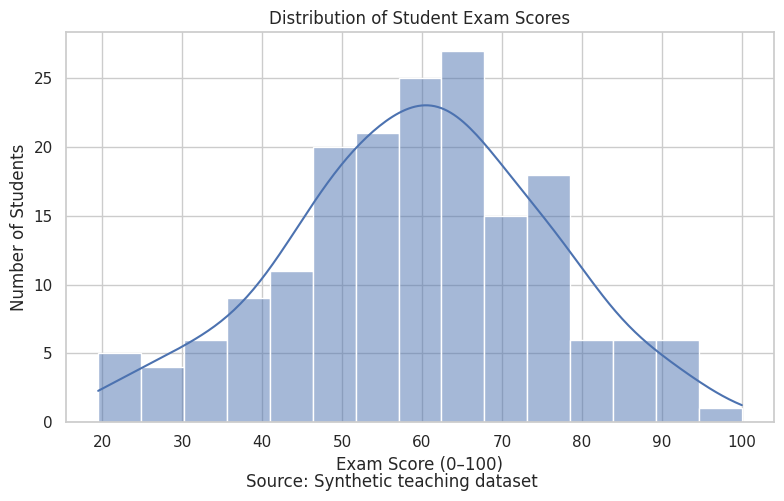

In [19]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="Exam_Score",
    bins=15,
    kde=True
)

plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score (0–100)")
plt.ylabel("Number of Students")
plt.figtext(0.5, 0.01, "Source: Synthetic teaching dataset",
            ha="center")

plt.tight_layout()
plt.show()


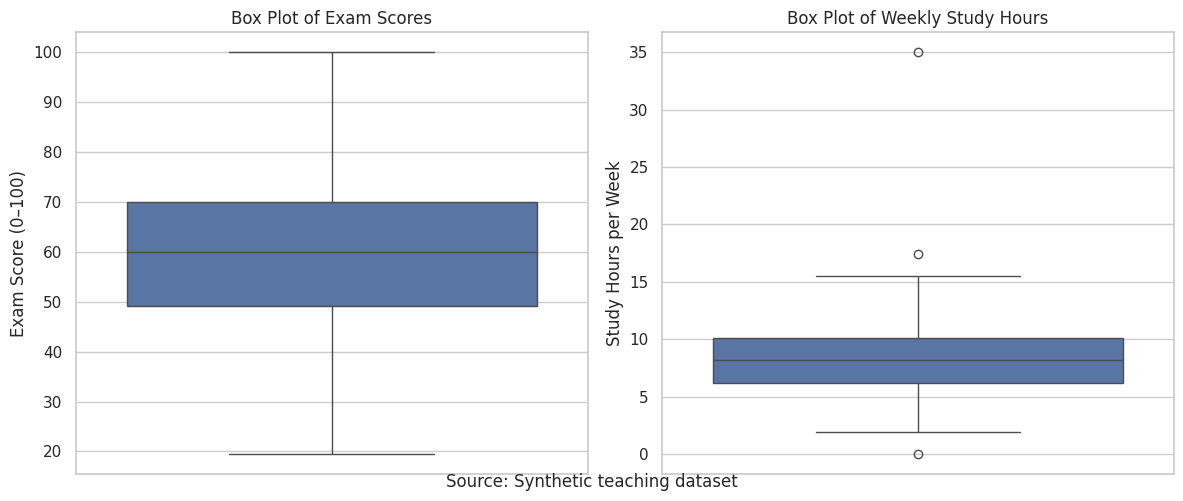

In [20]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df_clean, y="Exam_Score", ax=axes[0])
axes[0].set_title("Box Plot of Exam Scores")
axes[0].set_ylabel("Exam Score (0–100)")

sns.boxplot(
    data=df_clean,
    y="Study_Hours_Per_Week",
    ax=axes[1]
)
axes[1].set_title("Box Plot of Weekly Study Hours")
axes[1].set_ylabel("Study Hours per Week")

fig.text(0.5, 0.01, "Source: Synthetic teaching dataset",
         ha="center")

plt.tight_layout()
plt.show()



In [22]:

for column in ["Exam_Score", "Study_Hours_Per_Week"]:
    values = df_clean[column].dropna()

    print(f"\n{column}")
    print("Mean:", round(values.mean(), 2))
    print("Median:", round(values.median(), 2))
    print("Skewness:", round(values.skew(), 3))



Exam_Score
Mean: 59.39
Median: 60.0
Skewness: -0.133

Study_Hours_Per_Week
Mean: 8.36
Median: 8.2
Skewness: 2.456


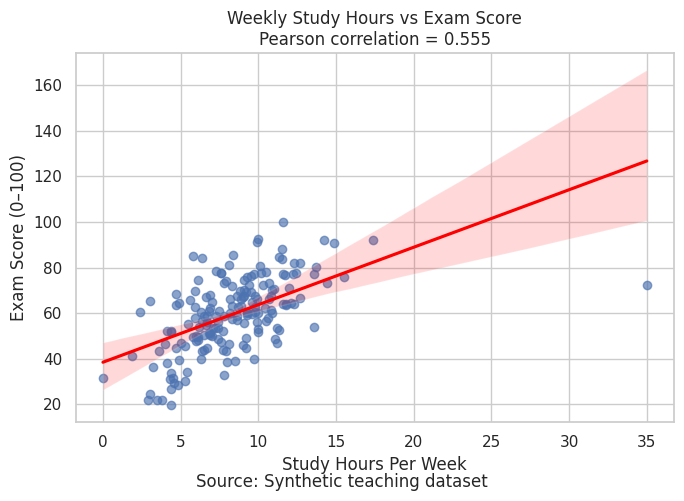

Pearson correlation (Study_Hours_Per_Week vs Exam_Score): 0.555


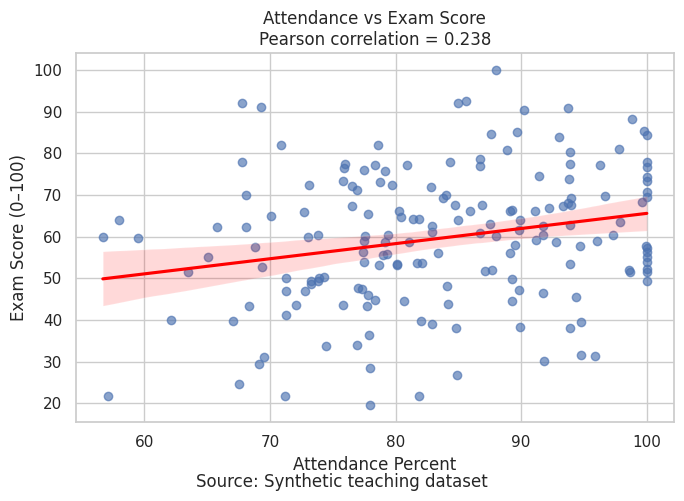

Pearson correlation (Attendance_Percent vs Exam_Score): 0.238


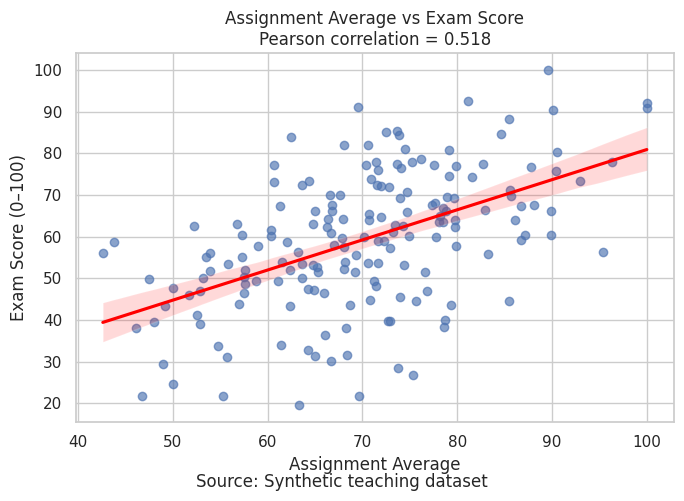

Pearson correlation (Assignment_Average vs Exam_Score): 0.518


In [23]:

relationships = [
    ("Study_Hours_Per_Week", "Exam_Score",
     "Weekly Study Hours vs Exam Score"),
    ("Attendance_Percent", "Exam_Score",
     "Attendance vs Exam Score"),
    ("Assignment_Average", "Exam_Score",
     "Assignment Average vs Exam Score")
]

for x_col, y_col, title in relationships:
    plot_data = df_clean[[x_col, y_col]].dropna()

    plt.figure(figsize=(7, 5))

    sns.regplot(
        data=plot_data,
        x=x_col,
        y=y_col,
        scatter_kws={"alpha": 0.65},
        line_kws={"color": "red"}
    )

    correlation = plot_data[x_col].corr(plot_data[y_col])

    plt.title(f"{title}\nPearson correlation = {correlation:.3f}")
    plt.xlabel(x_col.replace("_", " "))
    plt.ylabel("Exam Score (0–100)")
    plt.figtext(0.5, 0.01,
                "Source: Synthetic teaching dataset",
                ha="center")

    plt.tight_layout()
    plt.show()

    print(f"Pearson correlation ({x_col} vs Exam_Score): "
          f"{correlation:.3f}")



Exam score summaries by Programme


,count,mean,median,std
Programme,,,,
Statistics,45,63.09,63.1,16.26
Data Science,45,59.88,60.2,16.19
IT,45,57.71,57.8,14.97
Computer Science,45,56.88,56.4,17.25


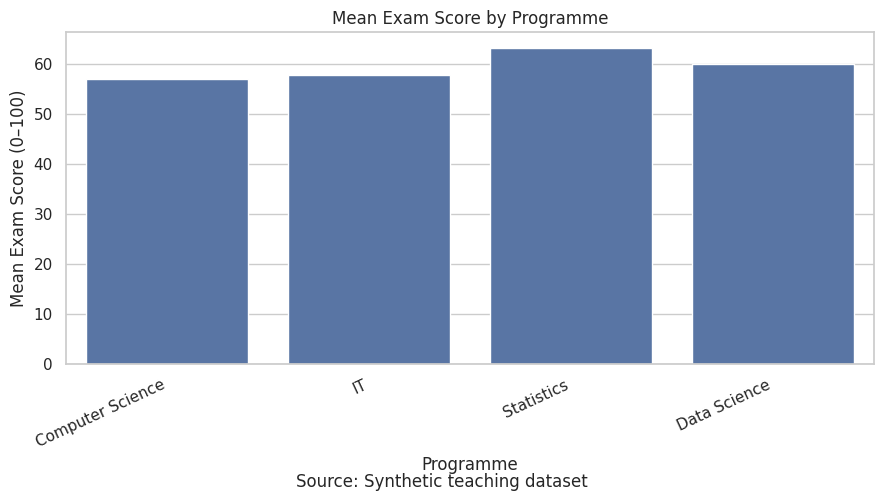


Exam score summaries by Device_Access


,count,mean,median,std
Device_Access,,,,
Phone only,20,64.17,62.25,16.39
Laptop,116,59.05,60.00,16.29
Shared computer,44,58.10,59.10,16.00


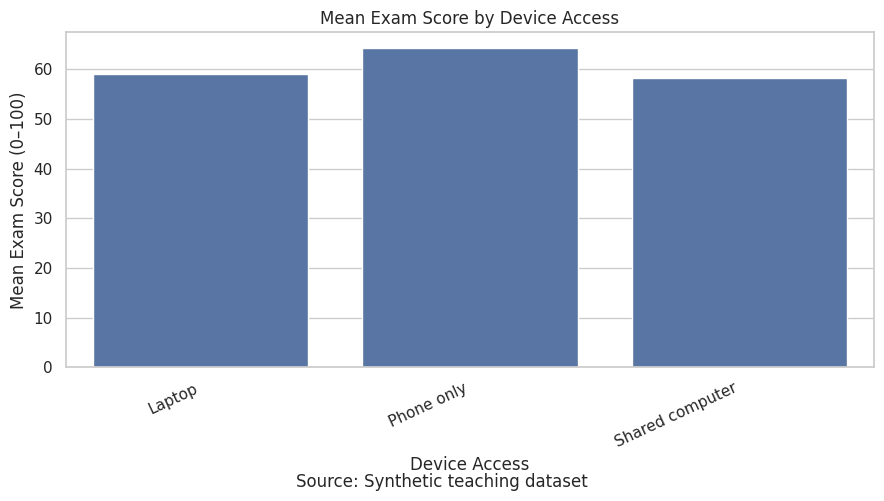


Exam score summaries by Internet_Access


,count,mean,median,std
Internet_Access,,,,
Limited,11,62.00,60.50,10.92
Reliable,115,59.57,59.70,15.82
Unknown,4,59.15,58.05,26.33
Intermittent,50,58.41,59.60,17.65


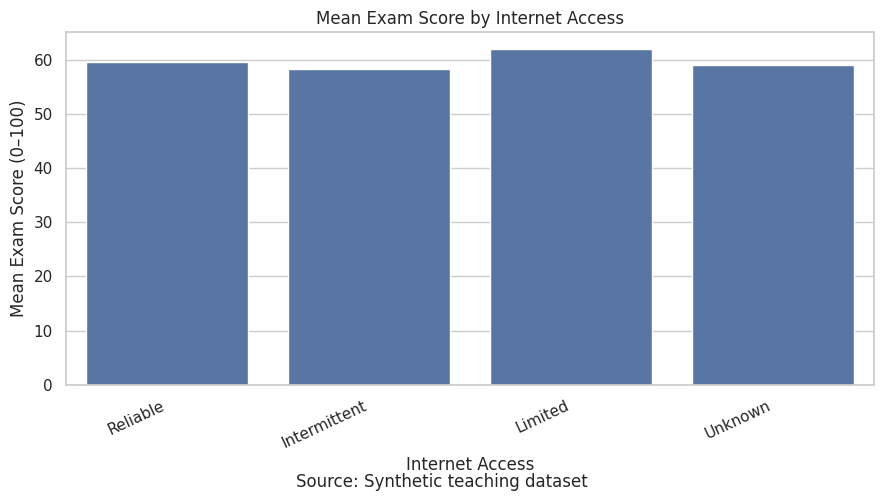

In [24]:

group_columns = [
    "Programme",
    "Device_Access",
    "Internet_Access"
]

for column in group_columns:
    group_summary = (
        df_clean.groupby(column, dropna=False)["Exam_Score"]
        .agg(["count", "mean", "median", "std"])
        .round(2)
        .sort_values("mean", ascending=False)
    )

    print(f"\nExam score summaries by {column}")
    display(group_summary)

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=df_clean,
        x=column,
        y="Exam_Score",
        errorbar=None
    )

    plt.title(f"Mean Exam Score by {column.replace('_', ' ')}")
    plt.xlabel(column.replace("_", " "))
    plt.ylabel("Mean Exam Score (0–100)")
    plt.xticks(rotation=25, ha="right")
    plt.figtext(0.5, 0.01,
                "Source: Synthetic teaching dataset",
                ha="center")

    plt.tight_layout()
    plt.show()



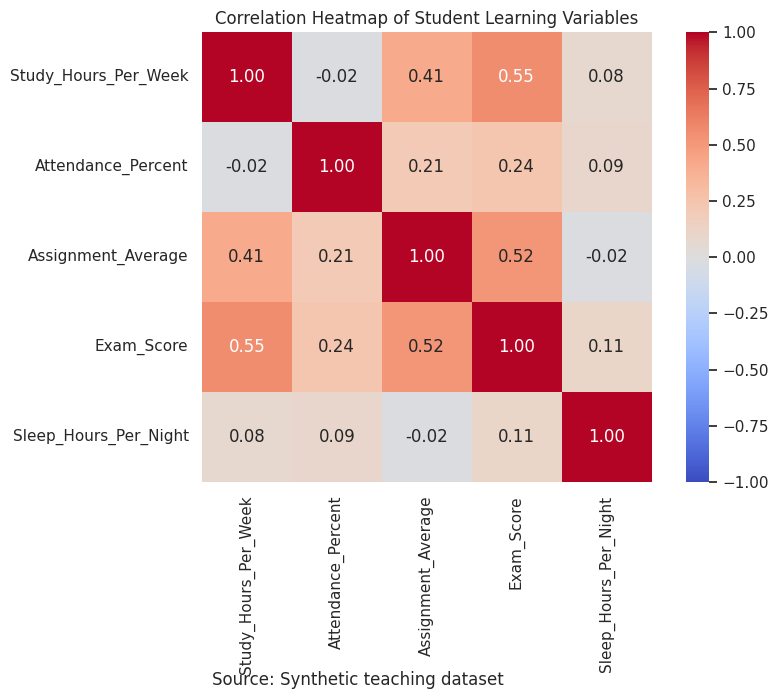

,Study_Hours_Per_Week,Attendance_Percent,Assignment_Average,Exam_Score,Sleep_Hours_Per_Night
Study_Hours_Per_Week,1.000,-0.018,0.409,0.555,0.078
Attendance_Percent,-0.018,1.000,0.208,0.238,0.087
Assignment_Average,0.409,0.208,1.000,0.518,-0.016
Exam_Score,0.555,0.238,0.518,1.000,0.106
Sleep_Hours_Per_Night,0.078,0.087,-0.016,0.106,1.000


In [25]:

corr_columns = [
    "Study_Hours_Per_Week",
    "Attendance_Percent",
    "Assignment_Average",
    "Exam_Score",
    "Sleep_Hours_Per_Night"
]

correlation_matrix = df_clean[corr_columns].corr(
    method="pearson"
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    square=True
)

plt.title("Correlation Heatmap of Student Learning Variables")
plt.figtext(0.5, 0.01,
            "Source: Synthetic teaching dataset",
            ha="center")

plt.tight_layout()
plt.show()

display(correlation_matrix.round(3))


In [26]:

from scipy import stats

exam_scores = df_clean["Exam_Score"].dropna()

n = len(exam_scores)
mean_score = exam_scores.mean()
std_score = exam_scores.std(ddof=1)

standard_error = std_score / np.sqrt(n)
critical_t = stats.t.ppf(0.975, df=n - 1)

lower_bound = mean_score - critical_t * standard_error
upper_bound = mean_score + critical_t * standard_error

print("Number of exam scores:", n)
print(f"Mean exam score: {mean_score:.2f}")
print(f"Standard deviation: {std_score:.2f}")
print(f"95% confidence interval: "
      f"({lower_bound:.2f}, {upper_bound:.2f})")


Number of exam scores: 180
Mean exam score: 59.39
Standard deviation: 16.23
95% confidence interval: (57.00, 61.78)


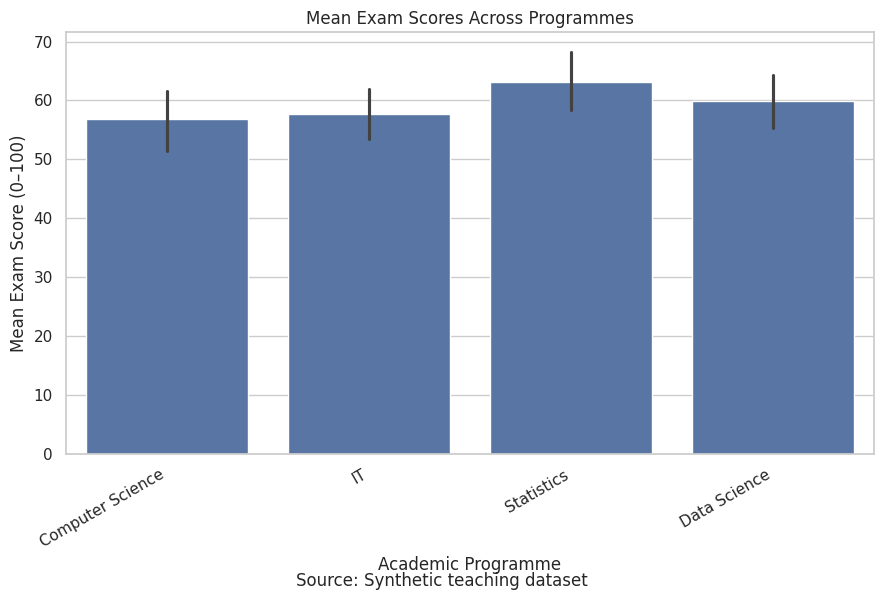

In [27]:

# Compare mean exam scores across programmes

plt.figure(figsize=(9, 6))

sns.barplot(
    data=df_clean,
    x="Programme",
    y="Exam_Score",
    errorbar=("ci", 95)
)

plt.title("Mean Exam Scores Across Programmes")
plt.xlabel("Academic Programme")
plt.ylabel("Mean Exam Score (0–100)")
plt.xticks(rotation=30, ha="right")
plt.figtext(
    0.5, 0.01,
    "Source: Synthetic teaching dataset",
    ha="center"
)

plt.tight_layout()
plt.show()


In [28]:

# Summary values for the findings brief

print("OVERALL EXAM PERFORMANCE")
print("Number of valid exam scores:",
      df_clean["Exam_Score"].count())
print("Mean:", round(df_clean["Exam_Score"].mean(), 2))
print("Median:", round(df_clean["Exam_Score"].median(), 2))
print("Standard deviation:",
      round(df_clean["Exam_Score"].std(), 2))

print("\nCORRELATIONS WITH EXAM SCORE")
for column in [
    "Study_Hours_Per_Week",
    "Attendance_Percent",
    "Assignment_Average",
    "Sleep_Hours_Per_Night"
]:
    pair = df_clean[[column, "Exam_Score"]].dropna()
    print(
        f"{column}: r = "
        f"{pair[column].corr(pair['Exam_Score']):.3f}; "
        f"n = {len(pair)}"
    )

print("\nMEAN EXAM SCORE BY PROGRAMME")
display(
    df_clean.groupby("Programme")["Exam_Score"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean", ascending=False)
)

print("\nMEAN EXAM SCORE BY DEVICE ACCESS")
display(
    df_clean.groupby("Device_Access")["Exam_Score"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print("\nMEAN EXAM SCORE BY INTERNET ACCESS")
display(
    df_clean.groupby("Internet_Access")["Exam_Score"]
    .agg(["count", "mean", "median"])
    .round(2)
)


OVERALL EXAM PERFORMANCE
Number of valid exam scores: 180
Mean: 59.39
Median: 60.0
Standard deviation: 16.23

CORRELATIONS WITH EXAM SCORE
Study_Hours_Per_Week: r = 0.555; n = 174
Attendance_Percent: r = 0.238; n = 175
Assignment_Average: r = 0.518; n = 175
Sleep_Hours_Per_Night: r = 0.106; n = 180

MEAN EXAM SCORE BY PROGRAMME


,count,mean,median
Programme,,,
Statistics,45,63.09,63.1
Data Science,45,59.88,60.2
IT,45,57.71,57.8
Computer Science,45,56.88,56.4



MEAN EXAM SCORE BY DEVICE ACCESS


,count,mean,median
Device_Access,,,
Laptop,116,59.05,60.00
Phone only,20,64.17,62.25
Shared computer,44,58.10,59.10



MEAN EXAM SCORE BY INTERNET ACCESS


,count,mean,median
Internet_Access,,,
Intermittent,50,58.41,59.60
Limited,11,62.00,60.50
Reliable,115,59.57,59.70
Unknown,4,59.15,58.05


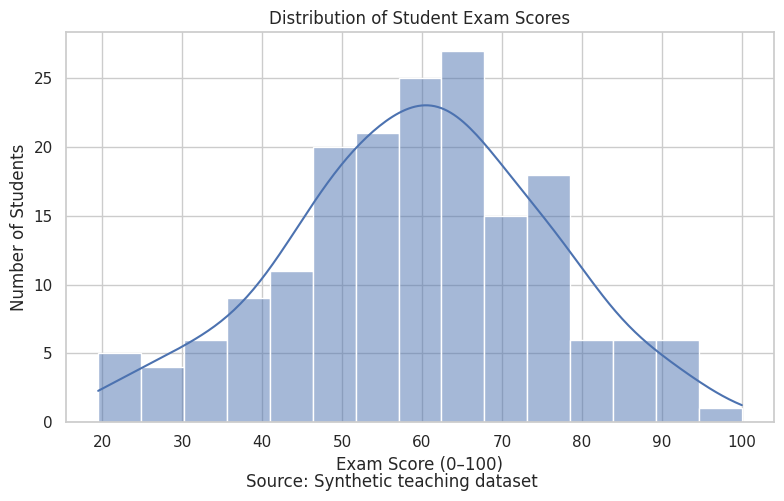

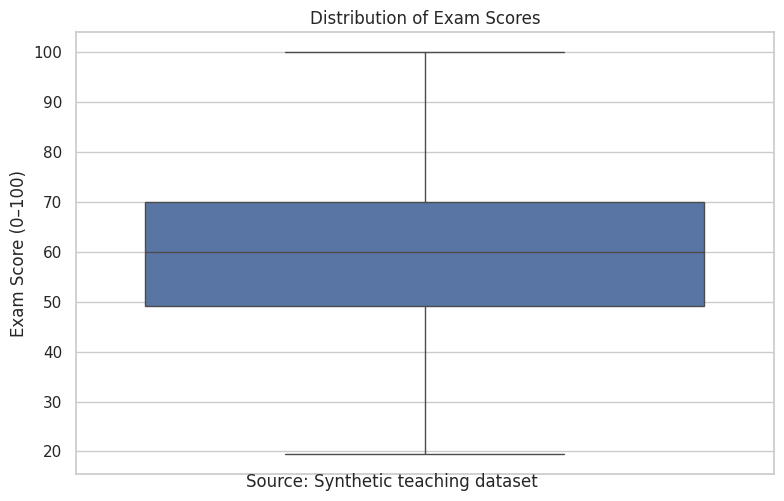

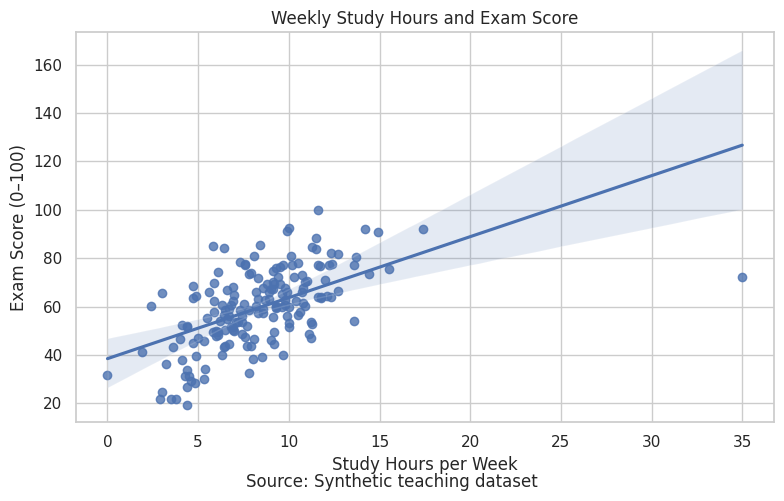

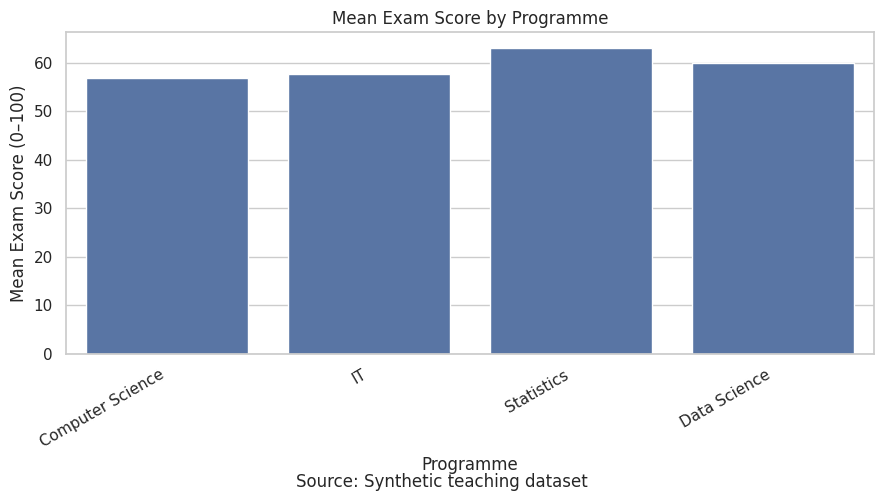

Figures saved in /content/assignment_figures


In [29]:

import os

# Create a folder for figures
os.makedirs("/content/assignment_figures", exist_ok=True)

# Save an exam score histogram
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="Exam_Score", bins=15, kde=True)
plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score (0–100)")
plt.ylabel("Number of Students")
plt.figtext(0.5, 0.01, "Source: Synthetic teaching dataset",
            ha="center")
plt.tight_layout()
plt.savefig("/content/assignment_figures/exam_histogram.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Save an exam score box plot
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, y="Exam_Score")
plt.title("Distribution of Exam Scores")
plt.ylabel("Exam Score (0–100)")
plt.figtext(0.5, 0.01, "Source: Synthetic teaching dataset",
            ha="center")
plt.tight_layout()
plt.savefig("/content/assignment_figures/exam_boxplot.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Save a scatter plot
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df_clean,
    x="Study_Hours_Per_Week",
    y="Exam_Score"
)
plt.title("Weekly Study Hours and Exam Score")
plt.xlabel("Study Hours per Week")
plt.ylabel("Exam Score (0–100)")
plt.figtext(0.5, 0.01, "Source: Synthetic teaching dataset",
            ha="center")
plt.tight_layout()
plt.savefig("/content/assignment_figures/study_vs_exam.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Save a categorical comparison chart
plt.figure(figsize=(9, 5))
sns.barplot(
    data=df_clean,
    x="Programme",
    y="Exam_Score",
    errorbar=None
)
plt.title("Mean Exam Score by Programme")
plt.xlabel("Programme")
plt.ylabel("Mean Exam Score (0–100)")
plt.xticks(rotation=30, ha="right")
plt.figtext(0.5, 0.01, "Source: Synthetic teaching dataset",
            ha="center")
plt.tight_layout()
plt.savefig("/content/assignment_figures/programme_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Figures saved in /content/assignment_figures")
